In [ ]:
import marimo as mo
import polars as pl
import re
import altair as alt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import NMF
from bertopic import BERTopic

/home/rickson/Analise-sentimentos/projetorafo/.venv/lib/python3.14/site-packages/bertopic/plotting/_datamap.py:10: UserWarning: Data map plotting is unavailable unless datamapplot is installed.
  warn("Data map plotting is unavailable unless datamapplot is installed.")


# Exploração dos RAFO

**Contexto**: RAFO é o termo que o Sanderson usa em Q&As (WOBs) para indicar
que uma pergunta é spoiler — mas também pode significar que a pergunta foi
muito boa, ou que revela o plot de algum livro próximo/distante.

## Perguntas que guiam esta análise

- Qual tipo de pergunta gera RAFO?
- As perguntas que geram RAFO mudaram com o tempo e com os lançamentos?
- Qual o RAFO mais antigo ainda não resolvido?
- Qual a frequência de RAFOs por ano?
- Como os RAFOs se comportam antes/depois do lançamento de um livro?
- Como os RAFOs mudaram em relação a termos de Realmatics (Connection,
  Intent, Identity, Investiture, Physical/Cognitive/Spiritual Realm)?

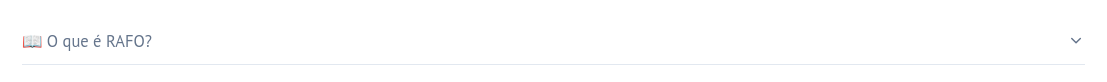

In [ ]:
mo.accordion({
    "📖 O que é RAFO?": mo.md(r"""
    **Coppermind**: RAFO is a term Brandon Sanderson uses at signings as a
    non-answer for prying 17th Sharders and others. It means "Read and Find Out."

    Robert Jordan popularized this term in this genre, and Brandon "inherited" it.
    Brandon feels bad for simply stating "No, I won't answer.", so he has the
    RAFO cards made physically. Instead of saying it, he hands out the cards to
    the fans, and as such **it has become a sort of trophy hunt for them.**

    RAFO can also be used as a response to questions that are meant to be
    discussed by fans or ones that will never be answered.
    """)
})

In [ ]:
livros_meta = pl.DataFrame({
    "livro": [
        "elantris", "final empire", "well of ascension", "hero of ages",
        "warbreaker", "way of kings", "alloy of law", "emperors soul",
        "shadows for silence", "words of radiance", "sixth of the dusk",
        "shadows of self", "bands of mourning", "secret history",
        "arcanum unbounded", "white sand", "oathbringer", "dawnshard",
        "rhythm of war", "lost metal", "tress", "yumi", "sunlit man",
        "wind and truth", "isles of the emberdark", "the fires of december",
    ],
    "ano": [
        2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2014,
        2015, 2016, 2016, 2016, 2016, 2017, 2020, 2020, 2022, 2023, 2023,
        2023, 2024, 2025, 2026,
    ],
    "serie": [
        "elantris", "mistborn era 1", "mistborn era 1", "mistborn era 1",
        "warbreaker", "stormlight", "mistborn era 2", "standalone",
        "standalone", "stormlight", "standalone", "mistborn era 2",
        "mistborn era 2", "mistborn era 2", "coletanea", "white sand",
        "stormlight", "stormlight", "stormlight", "mistborn era 2",
        "hoid's travails", "hoid's travails", "hoid's travails",
        "stormlight", "hoid's travails", "hoid's travails",
    ],
    "era": [
        "pre-rafo", "pre-rafo", "pre-rafo", "pre-rafo", "pre-rafo",
        "pre-rafo", "pre-rafo", "pre-rafo", "pre-rafo",
        "era rafo", "era rafo", "era rafo", "era rafo", "era rafo",
        "era rafo", "era rafo", "era rafo",
        "late cosmere", "late cosmere", "late cosmere",
        "late cosmere", "late cosmere", "late cosmere",
        "late cosmere", "late cosmere", "late cosmere",
    ],
})

In [ ]:
# ─── Vocabulário Cosmere (usado como vocabulário do CountVectorizer) ───
personagens = {
    'kaladin', 'shallan', 'dalinar', 'adolin', 'kelsier', 'vin', 'elend',
    'sazed', 'hoid', 'wit', 'wayne', 'wax', 'marasi', 'raoden', 'sarene',
    'vasher', 'vivenna', 'susebron', 'lightsong', 'khriss', 'nazh',
    'szeth', 'lift', 'navani', 'jasnah', 'renarin', 'gavilar', 'taravangian',
    'moash', 'teft', 'rock', 'lopen', 'pattern', 'syl', 'spook', 'ham',
    'breeze', 'clubs', 'dockson', 'marsh', 'tensoon', 'straff', 'zane',
    'tress', 'yumi', 'nomad', 'sigzil', 'rira', 'gawx', 'paina',
    'retribution', 'raboniel', 'talenel', 'talenelat', 'taln', 'kaminah',
    'makibak', 'rahel', 'aux', 'cinder king', 'painter', 'nikaro', 'glorf',
    'charlie', 'sorceress', 'riina', 'twinsoul', 'frost', 'dlavil', 'ulaam',
    'medelantorius', 'dedelin', 'jezrien', 'nale', 'chanarach', 'battar',
    'kalak', 'shalash', 'ishar', 'vedel', 'pailiah',
}
planetas = {
    'scadrial', 'roshar', 'sel', 'nalthis', 'taldain', 'threnody',
    'yolen', 'ashyn', 'braize', 'canticle', 'komashi', 'lumar',
    'first of the sun', 'drominad', 'shadesmar', 'urithiru', 'kholinar',
    'luthadel', 'elantris', 'hallandren', "t'telir", 'azir', 'jah keved',
    'alethkar', 'thaylenah', 'herdaz', 'aimia', 'shinovar', 'miral',
    'dhatri', 'utol', 'kite planet', 'ocean in the sky planet',
    'freefall planet', 'dragonrider planet', 'reliquary',
}
livros = {
    'mistborn', 'elantris', 'warbreaker', 'stormlight', 'cosmere',
    'way of kings', 'words of radiance', 'oathbringer', 'rhythm of war',
    'wind and truth', 'final empire', 'well of ascension', 'hero of ages',
    'alloy of law', 'shadows of self', 'bands of mourning', 'lost metal',
    'edgedancer', 'dawnshard', 'tress', 'yumi', 'sunlit man',
    'sixth of the dusk', 'shadows for silence', 'emperors soul',
    'secret history', 'white sand', 'the fires of december',
    'isles of the emberdark', "hoid's travails", 'blightfall',
    'the sunlit man',
}
lore = {
    'shard', 'adonalsium', 'investiture', 'allomancy', 'feruchemy',
    'hemalurgy', 'surgebinding', 'stormlight', 'spren', 'radiant',
    'honor', 'preservation', 'ruin', 'odium', 'cultivation', 'endowment',
    'autonomy', 'ambition', 'dominion', 'devotion', 'whimsy', 'valor',
    'invention', 'mercy', 'virtuosity', 'reason', 'voidbringer',
    'parshmen', 'singers', 'listener', 'mistborn', 'coinshot',
    'lurcher', 'thug', 'soother', 'rioter', 'seeker', 'smoker',
    'bondsmith', 'windrunner', 'skybreaker', 'edgedancer', 'truthwatcher',
    'lightweaver', 'elsecaller', 'willshaper', 'stoneward', 'dustbringer',
    'compound', 'fullborn', 'retribution',
    'yoki-hijo', 'yoki hijo', 'hion', 'hion lines', 'shroud', 'nightmare',
    'nightmare painter',
    'aether', 'aetherbound', 'aether spores', 'luhel bond', 'sprouter',
    'midnight spores', 'midnight essence', 'verdant', 'roseite',
    'crimson', 'zephyr',
    'embers', 'ember men', 'ember women', 'chorus', 'charred',
    'grand knell', 'emberdark', 'unsea', 'intensifier',
    'negative investiture', 'awakened metalminds',
    'ati', 'leras', 'tanavast', 'koravellium avast', 'edgli', 'bavadin',
    'shattering', 'vessel', 'intent', 'dawnshards', 'change', 'survive',
    'unite', 'divide',
    'microkinesis', 'knacks',
    'axon', 'axi', 'kinetic investiture', 'anti-investiture', 'surge',
    'gravitation', 'adhesion', 'cohesion', 'tension', 'progression',
    'illumination', 'transformation', 'transportation', 'division',
    'abrasion',
    'nightwatcher', 'stormfather', 'sibling',
    'nahel bond', 'cognitive realm', 'physical realm', 'spiritual realm',
}
dragonsteel_funcionarios = [
    "Brandon Sanderson", "Peter Ahlstrom", "Isaac Stewart", "Dan Wells",
    "Karen Ahlstrom", "Adam Horne", "Emily Sanderson", "Kara Stewart",
    "Matt Hatch", "Kathy",
]

dragonsteel_lowercase = [x.lower() for x in dragonsteel_funcionarios]
vocabulario = personagens | planetas | livros | lore

In [ ]:

mapa_era = livros_meta.select("ano", "era").unique(subset=["ano"])

In [ ]:
df = (
    pl.scan_parquet("data/processed/wobs_limpos.parquet")
      .join(mapa_era.lazy(), left_on="adicionado_ano", right_on="ano", how="left")
      .collect()
)

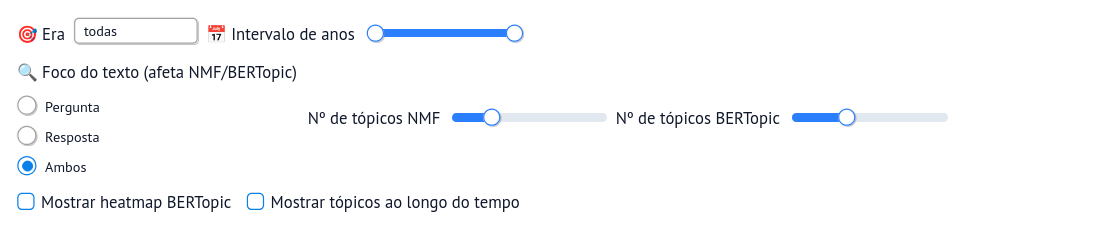

In [ ]:
_anos = df.select(pl.col("date").dt.year()).drop_nulls()
_ano_min = int(_anos.min().item())
_ano_max = int(_anos.max().item())

ctrl_era = mo.ui.dropdown(
    options=["todas", "pre-rafo", "era rafo", "late cosmere"],
    value="todas",
    label="🎯 Era",
)
ctrl_anos = mo.ui.range_slider(
    start=_ano_min, stop=_ano_max, value=(_ano_min, _ano_max), step=1,
    label="📅 Intervalo de anos",
)
ctrl_foco = mo.ui.radio(
    options=["Pergunta", "Resposta", "Ambos"],
    value="Ambos",
    label="🔍 Foco do texto (afeta NMF/BERTopic)",
)
ctrl_nmf = mo.ui.slider(
    start=2, stop=15, value=5, step=1,
    label="Nº de tópicos NMF",
)
ctrl_bert = mo.ui.slider(
    start=2, stop=20, value=8, step=1,
    label="Nº de tópicos BERTopic",
)
ctrl_heatmap = mo.ui.checkbox(value=False, label="Mostrar heatmap BERTopic")
ctrl_ro = mo.ui.checkbox(value=False, label="Mostrar tópicos ao longo do tempo")

mo.vstack([
    mo.hstack([ctrl_era, ctrl_anos], justify="start", gap="2rem"),
    mo.hstack([ctrl_foco, ctrl_nmf, ctrl_bert], justify="start", gap="2rem"),
    mo.hstack([ctrl_heatmap, ctrl_ro], justify="start", gap="2rem"),
])

In [ ]:
_lo, _hi = ctrl_anos.value
df_filt = df.filter(pl.col("date").dt.year().is_between(_lo, _hi))

if ctrl_era.value != "todas":
    df_filt = df_filt.filter(pl.col("era") == ctrl_era.value)

mo.md(
    f"**{len(df_filt):,}** registros após filtros "
    f"(era=`{ctrl_era.value}`, anos=`{_lo}–{_hi}`)."
)

<span class="markdown prose dark:prose-invert contents"><span class="paragraph"><strong>35,969</strong> registros após filtros (era=<code>todas</code>, anos=<code>2004–2026</code>).</span></span>

In [ ]:
_rafos = (
    df_filt.select(pl.col("tags").explode().unique())
           .filter(pl.col("tags").str.contains("rafo"))
           .to_series()
           .to_list()
)

expr_rafo = pl.any_horizontal(
    [pl.col("tags").list.contains(r) for r in _rafos]
).fill_null(False)

_padrao_dragonsteel = "|".join(re.escape(n) for n in dragonsteel_lowercase)
eh_dragonsteel = (
    pl.col("speaker")
      .str.to_lowercase()
      .str.contains(_padrao_dragonsteel)
      .fill_null(False)
)

df_rafo = (
    df_filt.with_columns(seq=pl.int_range(pl.len()).over("id"))
           .filter(expr_rafo)
)

perguntas_seq = (
    df_rafo.filter(~eh_dragonsteel)
           .select(
               "id", "seq",
               pl.col("speaker").alias("speaker_p"),
               pl.col("text").alias("pergunta"),
               "date",
           )
)
respostas_seq = (
    df_rafo.filter(eh_dragonsteel)
           .select(
               "id", "seq",
               pl.col("speaker").alias("speaker_r"),
               pl.col("text").alias("resposta"),
               "date",
           )
)

In [ ]:
dataset = (
    perguntas_seq
    .sort("id", "seq")
    .join_asof(
        respostas_seq.sort("id", "seq"),
        on="seq", by="id", strategy="forward",
    )
    .drop("seq")
    .filter(pl.col("resposta").is_not_null())
)

/tmp/marimo_34757/__marimo__cell_Kclp_.py:4: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  .join_asof(


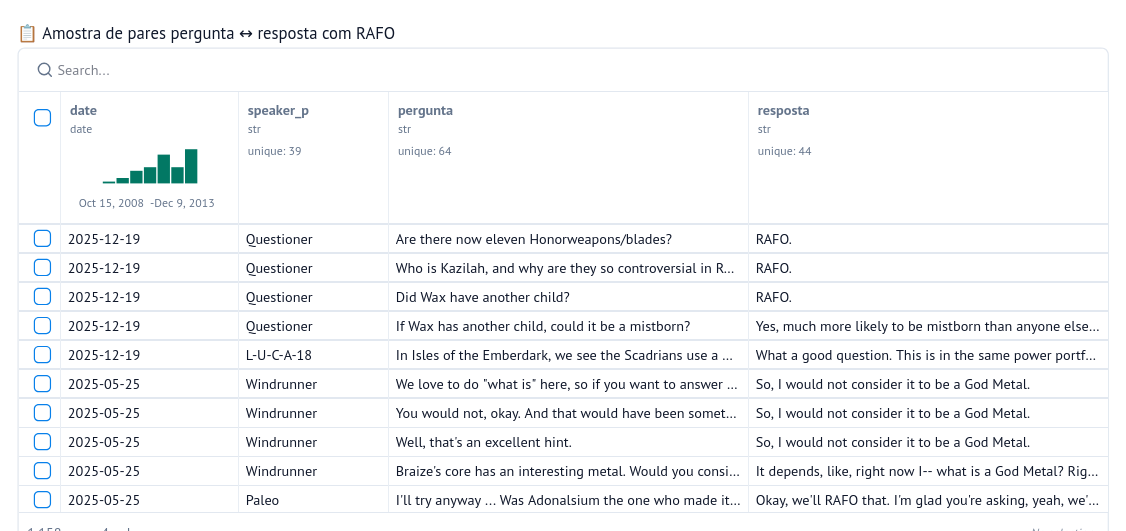

In [ ]:
mo.ui.table(
    dataset
      .select("date", "speaker_p", "pergunta", "resposta")
      .sort("date", descending=True),
    pagination=True,
    page_size=10,
    label="📋 Amostra de pares pergunta ↔ resposta com RAFO",
)

In [ ]:
_regex_ruido = (
    r"(?i)\b(okay|sighs|sighing|laughter|applause|yeah|little|know|like|"
    r"um|uh|inaudible|did|does|question|story|gonna|do|thats|right|rafo|"
    r"seen|going|look|new|just|the|of|that|to|is|in|it|and|are|you)\b"
)

def limpar(col):
    return (
        pl.col(col)
          .str.to_lowercase()
          .str.replace_all(r"[\(\[\{].*?[\)\]\}]", "")
          .str.replace_all(r"[^\w\s]", "")
          .str.replace_all(_regex_ruido, "")
          .str.replace_all(r"\s+", " ")
          .str.strip_chars()
    )

df_limpo = dataset.with_columns(
    limpar("pergunta").alias("pergunta_limpa"),
    limpar("resposta").alias("resposta_limpa"),
)

In [ ]:
match ctrl_foco.value:
    case "Pergunta":
        _texto = pl.col("pergunta_limpa")
    case "Resposta":
        _texto = pl.col("resposta_limpa")
    case _:
        _texto = pl.col("pergunta_limpa") + " " + pl.col("resposta_limpa")

df_text_full = df_limpo.with_columns(
    text_full=_texto,
    ano=pl.col("date").dt.year(),
)

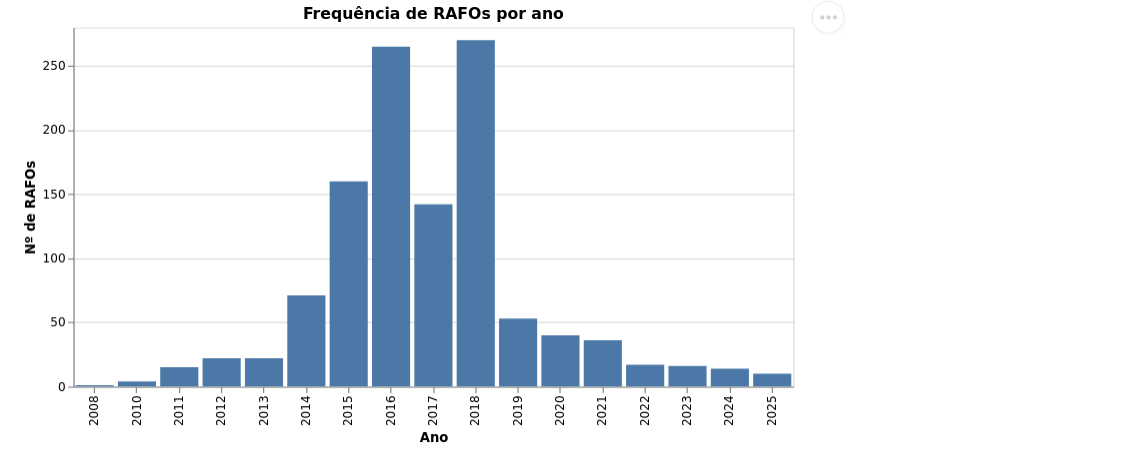

In [ ]:
_freq = (
    df_text_full
    .group_by("ano")
    .len()
    .sort("ano")
)

alt.Chart(_freq).mark_bar().encode(
    x=alt.X("ano:O", title="Ano"),
    y=alt.Y("len:Q", title="Nº de RAFOs"),
    tooltip=["ano", "len"],
).properties(
    title="Frequência de RAFOs por ano",
    width=600, height=300,
).interactive()

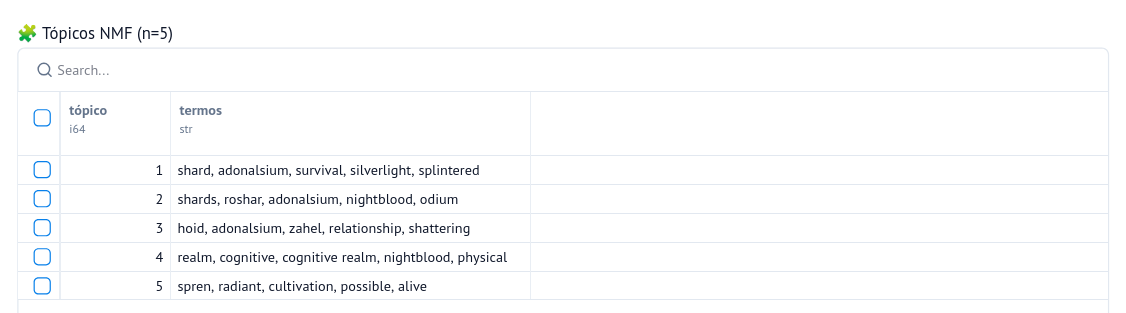

In [ ]:
_vetorizador = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_df=0.7,
    min_df=2,
)
_X = _vetorizador.fit_transform(df_limpo["pergunta_limpa"].to_list())

_nmf = NMF(n_components=ctrl_nmf.value, max_iter=1000, random_state=42)
_nmf.fit(_X)

_termos = _vetorizador.get_feature_names_out()
_linhas = []
for _i, _comp in enumerate(_nmf.components_):
    _top = _comp.argsort()[:-6:-1]
    _linhas.append({
        "tópico": _i + 1,
        "termos": ", ".join(_termos[j] for j in _top),
    })

mo.ui.table(
    pl.DataFrame(_linhas),
    pagination=False,
    label=f"🧩 Tópicos NMF (n={ctrl_nmf.value})",
)

In [ ]:
_vec = CountVectorizer(vocabulary=vocabulario)

topic_model = BERTopic(
    language="english",
    calculate_probabilities=True,
    verbose=True,
    vectorizer_model=_vec,
    nr_topics=ctrl_bert.value,
)

topics, probs = topic_model.fit_transform(df_text_full["text_full"].to_list())

2026-10-15 17:18:56,234 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|█████████████████████████████████| 37/37 [00:22<00:00,  1.64it/s]
2026-10-15 17:19:22,194 - BERTopic - Embedding - Completed ✓
2026-10-15 17:19:22,195 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-15 17:19:29,623 - BERTopic - Dimensionality - Completed ✓
2026-10-15 17:19:29,624 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-15 17:19:29,822 - BERTopic - Cluster - Completed ✓
2026-10-15 17:19:29,824 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
/home/rickson/Analise-sentimentos/projetorafo/.venv/lib/python3.14/site-packages/bertopic/vectorizers/_ctfidf.py:82: RuntimeWarning: divide by zero encountered in divide
  idf = np.log((avg_nr_samples / df) + 1)
2026-10-15 17:19:29,895 - BERTopic - Representation - Completed ✓
2026-10-15 17:19:29,897 - BERTopic - Topic reduction - Reducing number of

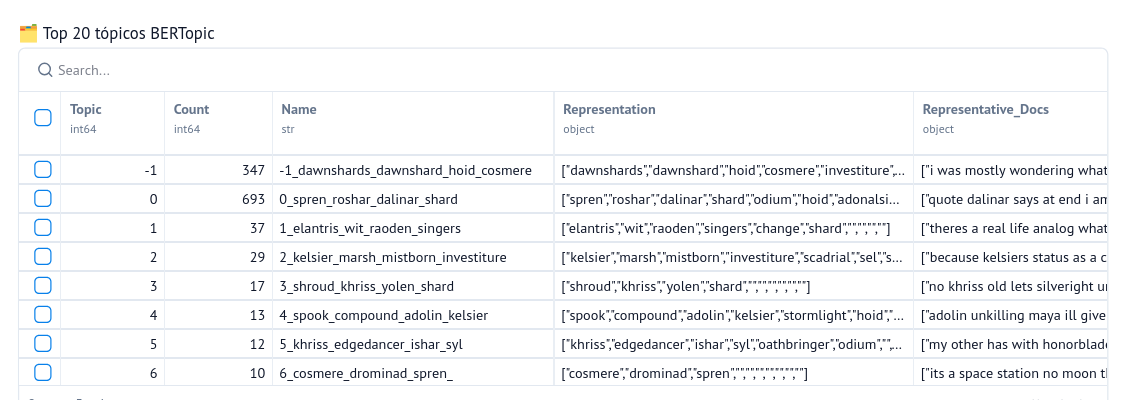

In [ ]:
mo.ui.table(
    topic_model.get_topic_info().head(20),
    pagination=False,
    label="🗂️ Top 20 tópicos BERTopic",
)

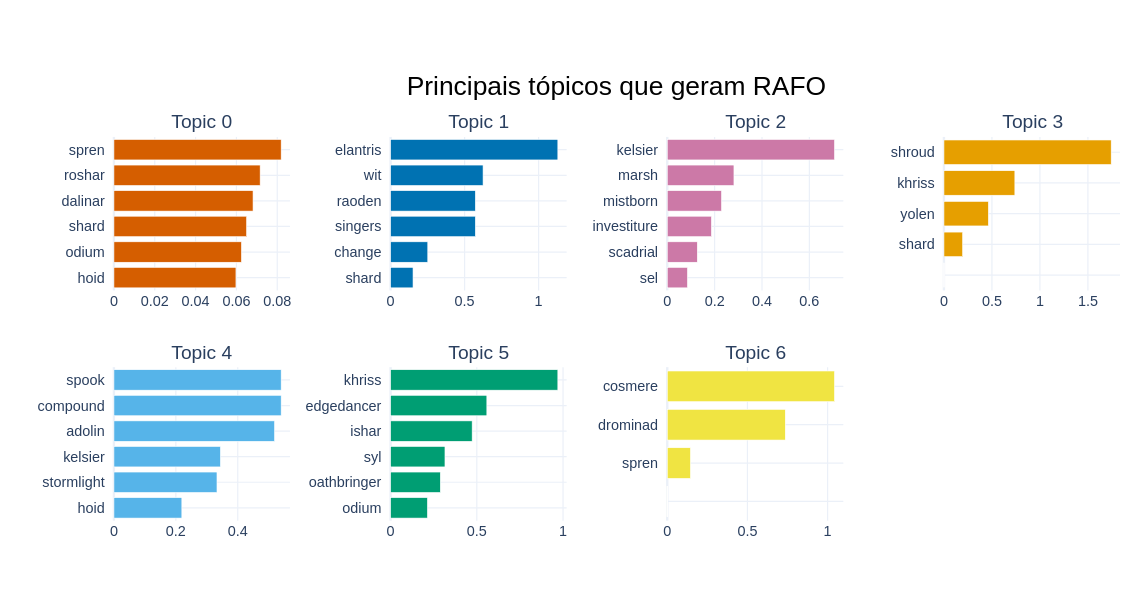

In [ ]:
topic_model.visualize_barchart(
    top_n_topics=min(ctrl_bert.value, 10),
    n_words=6,
    title="Principais tópicos que geram RAFO",
)

/home/rickson/Analise-sentimentos/projetorafo/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


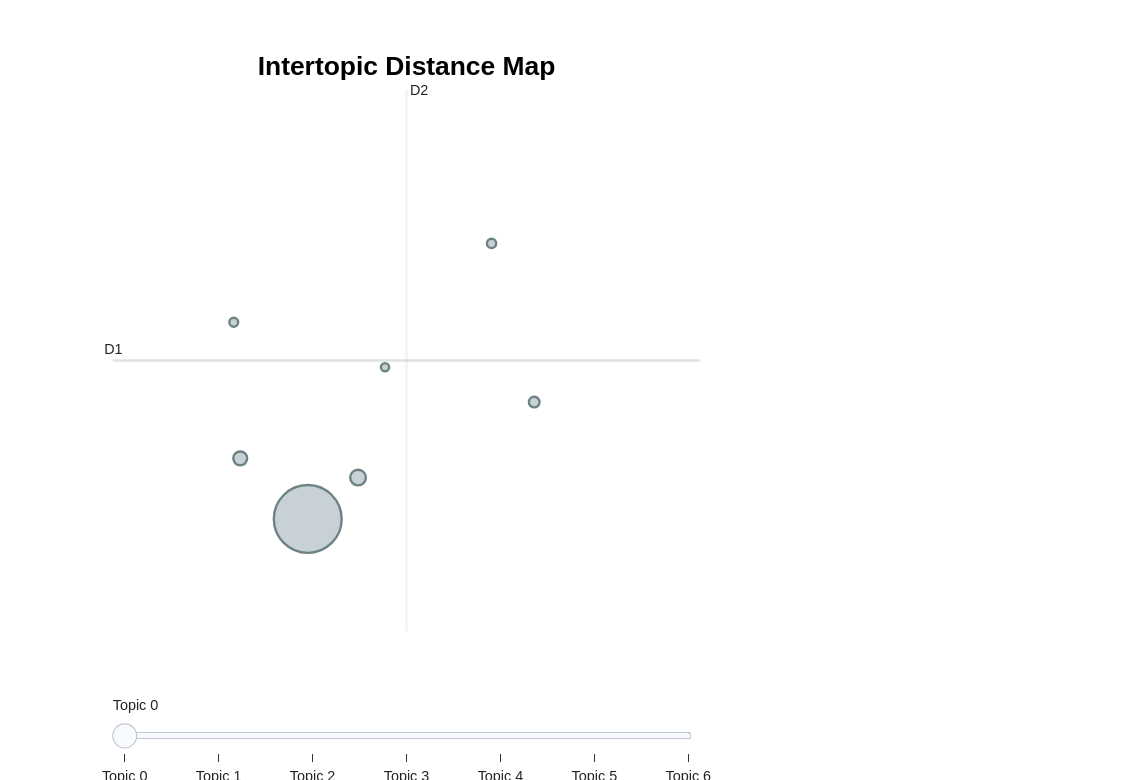

In [ ]:
topic_model.visualize_topics()

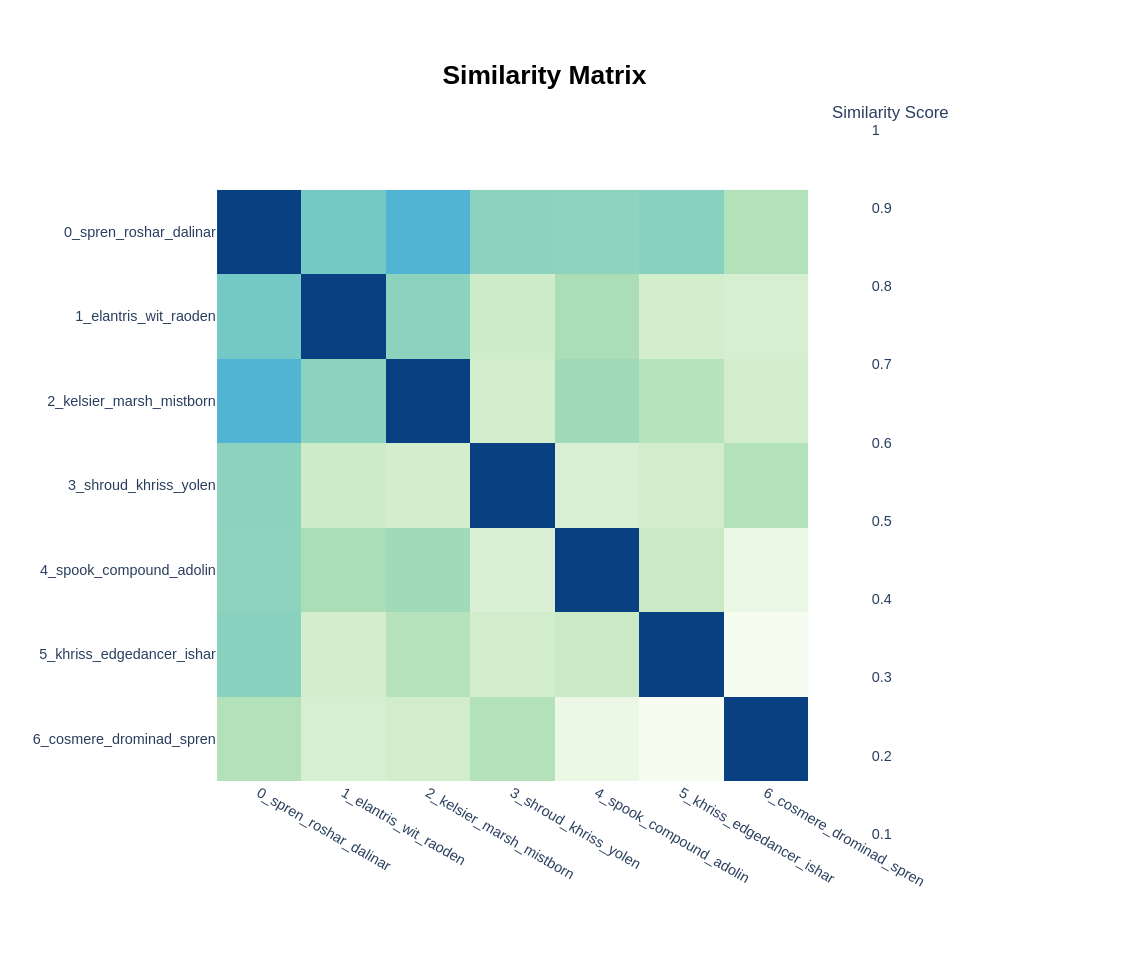

In [ ]:
ctrl_heatmap.value and topic_model.visualize_heatmap()

10it [00:00, 51.86it/s]


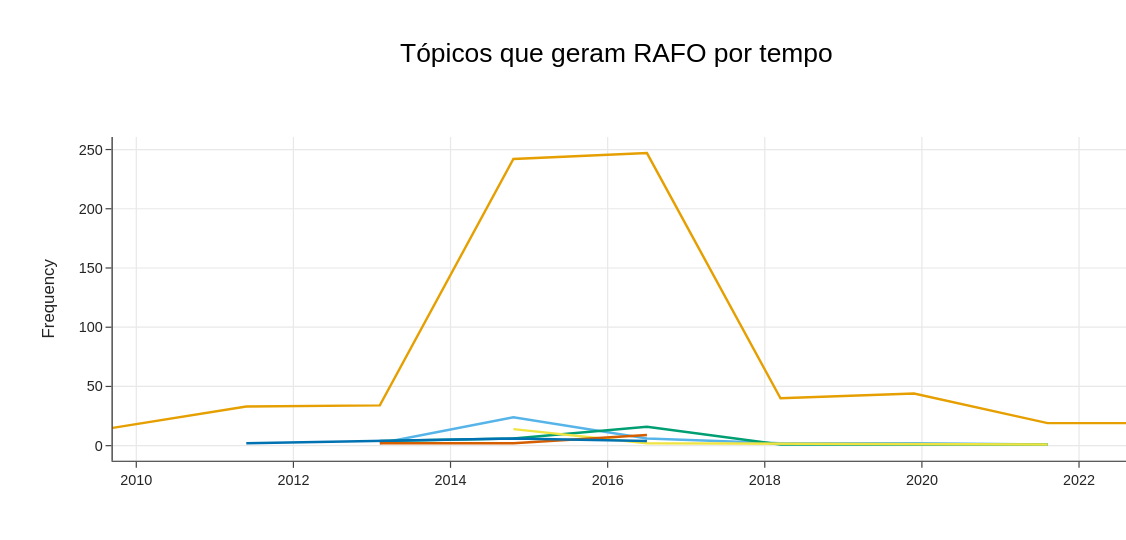

In [ ]:
_resultado = None
if ctrl_ro.value and len(df_text_full) > 0:
    _tot = topic_model.topics_over_time(
        df_text_full["text_full"].to_list(),
        timestamps=df_text_full["ano"].to_list(),
        nr_bins=10,
    )
    _resultado = topic_model.visualize_topics_over_time(
        _tot,
        top_n_topics=6,
        title="Tópicos que geram RAFO por tempo",
    )
_resultado